In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install qiskit ipywidgets

  Using cached jedi-0.19.1-py2.py3-none-any.whl.metadata (22 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 MB 17.1 MB/s eta 0:00:00
Using cached jedi-0.19.1-py2.py3-none-any.whl (1.6 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.5/108.5 kB 6.5 MB/s eta 0:00:00


In [3]:
!pip install qiskit-machine-learning

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.4/133.4 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.8/97.8 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.6/308.6 kB 9.6 MB/s eta 0:00:00
  Created wheel for fastdtw: filename=fastdtw-0.3.4-cp310-cp310-linux_x86_64.whl size=512548 sha256=ab89b50082895513ed4a0fd6606172373254c21015bdcc2a5cd2485956248c12
  Stored in directory: /root/.cache/pip/wheels/73/c8/f7/c25448dab74c3acf4848bc25d513c736bb93910277e1528ef4
Successfully built fastdtw


In [4]:
pip install qiskit-aer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 54.0 MB/s eta 0:00:00


In [5]:
!pip install pylatexenc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 3.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=3202343e3a651e61acd75157adaabab06cf5fe3252dd9c4e041fa37864a733ce
  Stored in directory: /root/.cache/pip/wheels/d3/31/8b/e09b0386afd80cfc556c00408c9aeea5c35c4d484a9c762fd5
Successfully built pylatexenc


In [6]:
import pandas as pd
##df = pd.read_csv('/content/drive/My Drive/CRWU/all_CRWU_feat_best_multiple.csv')
#df
df = pd.read_csv('/content/drive/MyDrive/crwu-qauntum/mrmr_best13_binary_1161.csv')
features = df.drop('Label', axis=1)
labels = df.Label
print('features: {}'.format(features.shape))
print('labels: {}'.format(labels.shape))

features: (2322, 13)
labels: (2322,)


In [7]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

features = MinMaxScaler(feature_range=(0, np.pi)).fit_transform(features)

train_features, test_features, train_labels, test_labels = train_test_split(
    features, labels, train_size=0.9, random_state=1234
)
print('train_features: {}'.format(train_features.shape))
print('test_features: {}'.format(test_features.shape))
adhoc_total=len(features)
print(adhoc_total)

train_features: (2089, 13)
test_features: (233, 13)
2322


In [8]:
import time
from qiskit_aer import Aer
from qiskit.circuit.library import ZFeatureMap
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import PegasosQSVC


# number of qubits is equal to the number of features
num_features = features.shape[1]
num_qubits = num_features

# number of steps performed during the training procedure
tau = 5
# regularization parameter
C = 1000

# Start timing for feature map creation
start_time = time.time()

# Step 1: Create the feature map
feature_map = ZFeatureMap(feature_dimension=num_qubits, reps=5)
end_time = time.time()
print(f"Time taken for feature map creation: {end_time - start_time:.4f} seconds")

# Start timing for quantum kernel creation
start_time = time.time()

# Step 2: Create the quantum kernel
qkernel = FidelityQuantumKernel(feature_map=feature_map)
end_time = time.time()
print(f"Time taken for quantum kernel creation: {end_time - start_time:.4f} seconds")

# Start timing for PegasosQSVC training
start_time = time.time()

# Step 3: Train PegasosQSVC
pegasos_qsvc = PegasosQSVC(quantum_kernel=qkernel, C=C, num_steps=tau)
pegasos_qsvc.fit(train_features, train_labels)
end_time = time.time()
print(f"Time taken for PegasosQSVC training: {end_time - start_time:.4f} seconds")


Time taken for feature map creation: 0.0011 seconds
Time taken for quantum kernel creation: 0.1717 seconds
Time taken for PegasosQSVC training: 1.3281 seconds


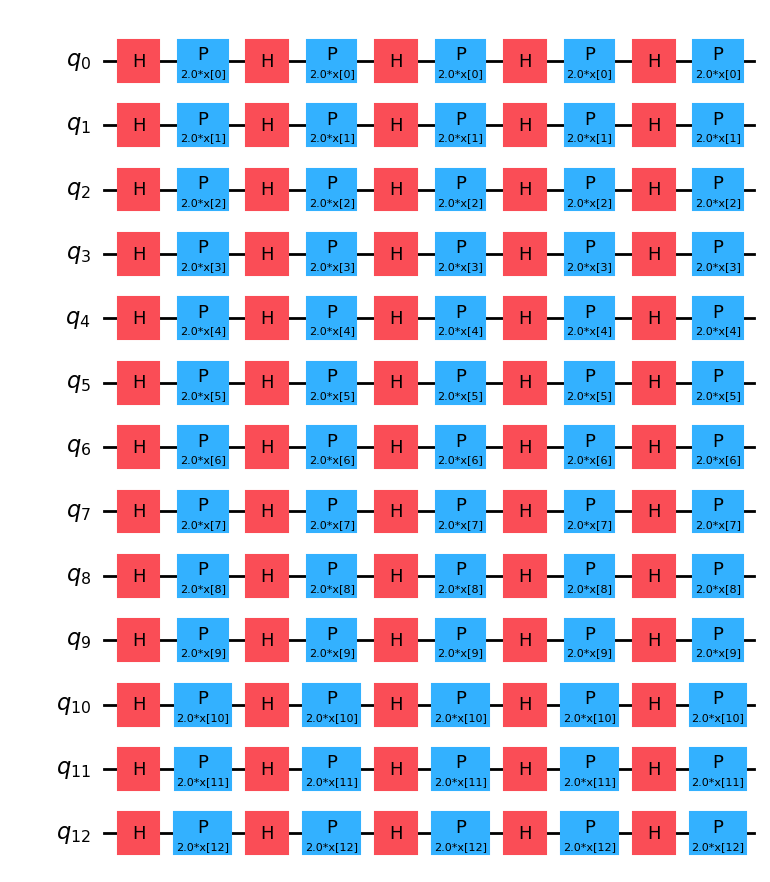

In [9]:
feature_map.decompose().draw(output="mpl")

In [10]:
import time
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Track time for training predictions
start_time = time.time()
train_predictions = pegasos_qsvc.predict(train_features)
train_prediction_time = time.time() - start_time

# Track time for test predictions
start_time = time.time()
test_predictions = pegasos_qsvc.predict(test_features)
test_prediction_time = time.time() - start_time

# Confusion Matrix for training data
train_cm = confusion_matrix(train_labels, train_predictions)
train_TN, train_FP, train_FN, train_TP = train_cm.ravel()

# Confusion Matrix for test data
test_cm = confusion_matrix(test_labels, test_predictions)
test_TN, test_FP, test_FN, test_TP = test_cm.ravel()

# Classification Metrics for training data
# Classification Metrics for training data
train_accuracy = accuracy_score(train_labels, train_predictions) * 100
train_precision = precision_score(train_labels, train_predictions, average='macro') * 100
train_recall = recall_score(train_labels, train_predictions, average='macro') * 100
train_f1 = f1_score(train_labels, train_predictions, average='macro') * 100

# Classification Metrics for test data
test_accuracy = accuracy_score(test_labels, test_predictions) * 100
test_precision = precision_score(test_labels, test_predictions, average='macro') * 100
test_recall = recall_score(test_labels, test_predictions, average='macro') * 100
test_f1 = f1_score(test_labels, test_predictions, average='macro') * 100


# Print classification metrics
print('--- Training Metrics ---')
print(f"TP: {train_TP}, TN: {train_TN}, FP: {train_FP} (Type I Error), FN: {train_FN} (Type II Error)")
print(f"Accuracy: {train_accuracy:.2f}%")
print(f"Precision: {train_precision:.2f}%")
print(f"Recall: {train_recall:.2f}%")
print(f"F1 Score: {train_f1:.2f}%")
print(f"Time taken for training predictions: {train_prediction_time:.4f} seconds")

print('\n--- Testing Metrics ---')
print(f"TP: {test_TP}, TN: {test_TN}, FP: {test_FP} (Type I Error), FN: {test_FN} (Type II Error)")
print(f"Accuracy: {test_accuracy:.2f}%")
print(f"Precision: {test_precision:.2f}%")
print(f"Recall: {test_recall:.2f}%")
print(f"F1 Score: {test_f1:.2f}%")
print(f"Time taken for test predictions: {test_prediction_time:.4f} seconds")

# Comparison table for metrics
comparison_table = {
    'Metric': ['TP', 'TN', 'FP (Type I)', 'FN (Type II)', 'Accuracy', 'Precision', 'Recall', 'F1 Score', 'Prediction Time (s)'],
    'Training': [train_TP, train_TN, train_FP, train_FN, train_accuracy, train_precision, train_recall, train_f1, f"{train_prediction_time:.4f}"],
    'Testing': [test_TP, test_TN, test_FP, test_FN, test_accuracy, test_precision, test_recall, test_f1, f"{test_prediction_time:.4f}"]
}

# Print comparison table
import pandas as pd
comparison_df = pd.DataFrame(comparison_table)
print('\n--- Comparison Table (Training vs Testing) ---')
print(comparison_df)


--- Training Metrics ---
TP: 1033, TN: 0, FP: 1056 (Type I Error), FN: 0 (Type II Error)
Accuracy: 49.45%
Precision: 24.72%
Recall: 50.00%
F1 Score: 33.09%
Time taken for training predictions: 1969.6048 seconds

--- Testing Metrics ---
TP: 128, TN: 0, FP: 105 (Type I Error), FN: 0 (Type II Error)
Accuracy: 54.94%
Precision: 27.47%
Recall: 50.00%
F1 Score: 35.46%
Time taken for test predictions: 212.8046 seconds

--- Comparison Table (Training vs Testing) ---
                Metric   Training    Testing
0                   TP       1033        128
1                   TN          0          0
2          FP (Type I)       1056        105
3         FN (Type II)          0          0
4             Accuracy  49.449497  54.935622
5            Precision  24.724749  27.467811
6               Recall       50.0       50.0
7             F1 Score  33.087764  35.457064
8  Prediction Time (s)  1969.6048   212.8046


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
